# Caso Manaco – Estación 2: Diagnóstico con Ciencia de Datos

**Objetivo:** explorar la base de comercio exterior de calzado y convertir los resultados en hallazgos útiles para la Gerencia de Manaco.

Pasos (según el caso):
1. Revisar diccionario de datos, tipos de variables, valores faltantes y registros agregados.
2. Separar registros "Mundo" de los registros por país (evitar doble conteo).
3. Calcular valor y cantidad por flujo y categoría; ordenar socios comerciales.
4. Calcular valor comercial aproximado por par y explicar sus limitaciones.
5. Construir 3 gráficos: importaciones vs exportaciones, principales socios y valor por par.
6. Síntesis: 3 hallazgos, 2 limitaciones y 1 pregunta estratégica.

> **Importante:** la base **no** contiene datos de Manaco ni de Bolivia. Son registros de comercio de calzado **reportados por España** (2020–2024). Se usan como *referencia externa* del mercado internacional.

## 0. Cargar librerías y el archivo Excel
En Colab, al ejecutar la celda se abrirá un botón para **subir el Excel** (`Bae_de_Datos_MANACO_-_INTERMEDIO_1.xlsx`).

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 200)

ARCHIVO = "Bae_de_Datos_MANACO_-_INTERMEDIO_1.xlsx"
if not os.path.exists(ARCHIVO):
    from google.colab import files  # solo existe en Colab
    subido = files.upload()
    ARCHIVO = next(iter(subido))

df_original = pd.read_excel(ARCHIVO)
print("Filas y columnas:", df_original.shape)
df_original.head()

Filas y columnas: (240, 10)


,País_reportante,Flujo_comercial,Año,Código_SA6,Categoría_calzado,Socio_comercial,Valor_miles_USD,Cantidad_pares,Valor_USD,Valor_USD_por_par
0,España,Importación,2023,640411,Calzado deportivo con suela de caucho/plástico,Indonesia,"62,576.67",2075438,"62,576,674.41",30.15
1,España,Importación,2024,640411,Calzado deportivo con suela de caucho/plástico,Estados Unidos,"36,379.51",1199546,"36,379,513.62",30.33
2,España,Importación,2022,640411,Calzado deportivo con suela de caucho/plástico,Grecia,"853,548.06",30537251,"853,548,057.31",27.95
3,España,Importación,2020,640411,Calzado deportivo con suela de caucho/plástico,Eslovaquia,"166,572.63",4861274,"166,572,626.51",34.27
4,España,Importación,2023,640411,Calzado deportivo con suela de caucho/plástico,Italia,"241,958.40",11767364,"241,958,400.09",20.56


## 1. Diccionario de datos
| Variable | Tipo | Descripción |
|---|---|---|
| País_reportante | Categórica | País que informa el comercio (siempre **España**) |
| Flujo_comercial | Categórica | Importación o Exportación |
| Año | Numérica discreta | 2020 a 2024 |
| Código_SA6 | Categórica (código) | Código arancelario del Sistema Armonizado a 6 dígitos |
| Categoría_calzado | Categórica | Descripción del código SA6 |
| Socio_comercial | Categórica | País de origen (importación) o destino (exportación) |
| Valor_miles_USD | Numérica continua | Valor comercial en miles de USD |
| Cantidad_pares | Numérica discreta | Número de pares |
| Valor_USD | Numérica continua | Valor comercial en USD (= miles × 1000) |
| Valor_USD_por_par | Numérica continua | Valor_USD / Cantidad_pares |

Códigos SA6: **640411** calzado deportivo (suela caucho/plástico) · **640399** suela caucho/plástico con parte superior de cuero · **640420** suela de cuero con parte superior de cuero.

In [2]:
print("Tipos de variables:\n", df_original.dtypes, sep="")
print("\nValores faltantes por columna:\n", df_original.isna().sum(), sep="")
print("\nFilas duplicadas exactas:", df_original.duplicated().sum())
for col in ["País_reportante", "Flujo_comercial", "Año", "Código_SA6"]:
    print(f"\n{col}:\n{df_original[col].value_counts().sort_index()}")
print("\nSocios comerciales distintos:", df_original["Socio_comercial"].nunique())

Tipos de variables:
País_reportante       object
Flujo_comercial       object
Año                    int64
Código_SA6             int64
Categoría_calzado     object
Socio_comercial       object
Valor_miles_USD      float64
Cantidad_pares         int64
Valor_USD            float64
Valor_USD_por_par    float64
dtype: object

Valores faltantes por columna:
País_reportante      0
Flujo_comercial      0
Año                  0
Código_SA6           0
Categoría_calzado    0
Socio_comercial      0
Valor_miles_USD      0
Cantidad_pares       0
Valor_USD            0
Valor_USD_por_par    0
dtype: int64

Filas duplicadas exactas: 0

País_reportante:
País_reportante
España    240
Name: count, dtype: int64

Flujo_comercial:
Flujo_comercial
Exportación    120
Importación    120
Name: count, dtype: int64

Año:
Año
2020    28
2021    34
2022    46
2023    50
2024    82
Name: count, dtype: int64

Código_SA6:
Código_SA6
640399    80
640411    80
640420    80
Name: count, dtype: int64

Socios comerciales 

## 2. Limpieza y validación

In [3]:
df = df_original.copy()

# 2.1 Quitar espacios sobrantes en textos
for col in df.select_dtypes("object"):
    df[col] = df[col].str.strip()

# 2.2 Código SA6 como texto (es un código, no un número para sumar)
df["Código_SA6"] = df["Código_SA6"].astype(str)

# 2.3 Nombre corto de categoría para gráficos
nombres_cortos = {"640411": "Deportivo (640411)",
                  "640399": "Caucho + cuero (640399)",
                  "640420": "Suela de cuero (640420)"}
df["Categoría_corta"] = df["Código_SA6"].map(nombres_cortos)

# 2.4 Registros agregados "Mundo"
es_mundo = df["Socio_comercial"].str.contains("Mundo|World", case=False)
print("Registros 'Mundo' encontrados:", es_mundo.sum())
df_mundo = df[es_mundo]
df = df[~es_mundo].copy()   # se trabaja solo con registros por país

# 2.5 Consistencia de columnas calculadas
dif_valor = (df["Valor_miles_USD"] * 1000 - df["Valor_USD"]).abs().max()
dif_par = (df["Valor_USD"] / df["Cantidad_pares"] - df["Valor_USD_por_par"]).abs().max()
print(f"Máx. diferencia Valor_miles×1000 vs Valor_USD: {dif_valor:.2f} USD (redondeo)")
print(f"Máx. diferencia del valor por par recalculado: {dif_par:.4f} USD (redondeo)")
print("Registros con cantidad 0 o negativa:", (df["Cantidad_pares"] <= 0).sum())
print("Registros con valor 0 o negativo:", (df["Valor_USD"] <= 0).sum())

Registros 'Mundo' encontrados: 0
Máx. diferencia Valor_miles×1000 vs Valor_USD: 4.98 USD (redondeo)
Máx. diferencia del valor por par recalculado: 0.0051 USD (redondeo)
Registros con cantidad 0 o negativa: 0
Registros con valor 0 o negativo: 0


In [4]:
# 2.6 Claves repetidas: mismo socio, año, flujo y código con valores distintos
clave = ["Socio_comercial", "Año", "Flujo_comercial", "Código_SA6"]
df["Clave_repetida"] = df.duplicated(clave, keep=False)
print("Registros con clave repetida:", df["Clave_repetida"].sum(),
      "(", df["Clave_repetida"].sum() // 2, "pares de registros )")
df[df["Clave_repetida"]].sort_values(clave)[clave + ["Valor_USD", "Cantidad_pares", "Valor_USD_por_par"]]

Registros con clave repetida: 20 ( 10 pares de registros )


,Socio_comercial,Año,Flujo_comercial,Código_SA6,Valor_USD,Cantidad_pares,Valor_USD_por_par
120,Austria,2023,Exportación,640399,"255,074,307.70",12134129,21.02
150,Austria,2023,Exportación,640399,"69,998,948.56",1255657,55.75
202,Bélgica,2023,Exportación,640420,"2,620,350.49",50578,51.81
232,Bélgica,2023,Exportación,640420,"2,270,076.17",76929,29.51
162,Eslovenia,2024,Importación,640420,"2,921,663.59",68946,42.38
192,Eslovenia,2024,Importación,640420,"4,940,989.29",110679,44.64
48,Estados Unidos,2020,Exportación,640411,"21,696,383.11",901775,24.06
78,Estados Unidos,2020,Exportación,640411,"25,633,204.33",1584001,16.18
87,Finlandia,2020,Importación,640399,"207,819,809.19",10029654,20.72
117,Finlandia,2020,Importación,640399,"278,066,867.57",12870216,21.61


**Decisión:** las claves repetidas **no son duplicados exactos** (tienen valores distintos), por lo que se **mantienen** y se marcan. Al sumar por flujo, categoría o socio el resultado es el mismo que si se consolidaran. Se reporta como limitación.

In [5]:
# 2.7 Valores atípicos del valor por par (regla del rango intercuartílico, por flujo y categoría)
def marcar_atipicos(g):
    q1, q3 = g.quantile(0.25), g.quantile(0.75)
    iqr = q3 - q1
    return (g < q1 - 1.5 * iqr) | (g > q3 + 1.5 * iqr)

df["Atípico_valor_par"] = df.groupby(["Flujo_comercial", "Código_SA6"])["Valor_USD_por_par"].transform(marcar_atipicos)
print("Registros atípicos en valor por par:", df["Atípico_valor_par"].sum())
df[df["Atípico_valor_par"]][["Flujo_comercial", "Año", "Categoría_corta", "Socio_comercial", "Cantidad_pares", "Valor_USD_por_par"]]

Registros atípicos en valor por par: 12


,Flujo_comercial,Año,Categoría_corta,Socio_comercial,Cantidad_pares,Valor_USD_por_par
64,Exportación,2022,Deportivo (640411),Francia,751020,55.96
82,Importación,2024,Caucho + cuero (640399),Irlanda,15340395,49.66
90,Importación,2021,Caucho + cuero (640399),República Checa,62406725,8.00
100,Importación,2022,Caucho + cuero (640399),Suiza,4695218,51.18
104,Importación,2022,Caucho + cuero (640399),Eslovenia,5235524,40.76
105,Importación,2024,Caucho + cuero (640399),Indonesia,881976,66.70
115,Importación,2022,Caucho + cuero (640399),Camboya,8468445,43.17
125,Exportación,2023,Caucho + cuero (640399),Eslovaquia,1710127,66.74
180,Importación,2021,Suela de cuero (640420),Francia,31372,95.64
182,Importación,2020,Suela de cuero (640420),Rumanía,9253,119.24


In [6]:
# 2.8 Registros por año (¿la base está balanceada?)
pd.crosstab(df["Año"], df["Flujo_comercial"], margins=True, margins_name="Total")

Flujo_comercial,Exportación,Importación,Total
Año,,,
2020,15,13,28
2021,19,15,34
2022,18,28,46
2023,26,24,50
2024,42,40,82
Total,120,120,240


Los años **no están balanceados** (2024 tiene casi 3 veces más registros que 2020), así que comparar totales por año como si fuera *crecimiento* sería engañoso.

## 3. Indicadores

In [7]:
def resumen(grupo):
    t = df.groupby(grupo).agg(Valor_USD=("Valor_USD", "sum"),
                              Cantidad_pares=("Cantidad_pares", "sum"),
                              Registros=("Valor_USD", "size"),
                              Socios=("Socio_comercial", "nunique"))
    t["Valor_millones_USD"] = t["Valor_USD"] / 1e6
    t["Pares_millones"] = t["Cantidad_pares"] / 1e6
    t["USD_por_par_ponderado"] = t["Valor_USD"] / t["Cantidad_pares"]
    return t

ind_flujo = resumen("Flujo_comercial")
display(ind_flujo[["Valor_millones_USD", "Pares_millones", "USD_por_par_ponderado", "Registros", "Socios"]])

imp = ind_flujo.loc["Importación"]; exp = ind_flujo.loc["Exportación"]
print(f"Balanza comercial (Exp - Imp): {(exp.Valor_USD - imp.Valor_USD)/1e6:,.1f} millones USD")
print(f"Tasa de cobertura (Exp / Imp): {exp.Valor_USD / imp.Valor_USD:.1%}")

,Valor_millones_USD,Pares_millones,USD_por_par_ponderado,Registros,Socios
Flujo_comercial,,,,,
Exportación,"10,917.35",410.77,26.58,120,30
Importación,"18,506.09",751.09,24.64,120,30


Balanza comercial (Exp - Imp): -7,588.7 millones USD
Tasa de cobertura (Exp / Imp): 59.0%


In [8]:
ind_cat = resumen(["Flujo_comercial", "Categoría_corta"])
ind_cat["% del valor del flujo"] = ind_cat["Valor_USD"] / ind_cat.groupby(level=0)["Valor_USD"].transform("sum") * 100
ind_cat["% de los pares del flujo"] = ind_cat["Cantidad_pares"] / ind_cat.groupby(level=0)["Cantidad_pares"].transform("sum") * 100
ind_cat[["Valor_millones_USD", "Pares_millones", "% del valor del flujo", "% de los pares del flujo", "USD_por_par_ponderado"]]

Valor_millones_USD  Pares_millones  % del valor del flujo  % de los pares del flujo  USD_por_par_ponderado
Flujo_comercial Categoría_corta                                                                                                                    
Exportación     Caucho + cuero (640399)            8,514.24          320.75                  77.99                     78.09                  26.54
                Deportivo (640411)                 2,173.93           84.49                  19.91                     20.57                  25.73
                Suela de cuero (640420)              229.19            5.53                   2.10                      1.35                  41.42
Importación     Caucho + cuero (640399)           11,709.68          497.50                  63.27                     66.24                  23.54
                Deportivo (640411)                 6,447.48          245.87                  34.84                     32.74                  26.22
                Suela de cuero (640420)              348.93            7.72                   1.89                      1.03                  45.22

**¿Cambian las conclusiones si se compara valor frente a cantidad?** Sí: *Suela de cuero (640420)* representa muy poco de los pares, pero su peso en valor es mayor que su peso en cantidad, porque cada par vale casi el doble. En volumen domina *Caucho + cuero (640399)*.

In [9]:
# Ranking de socios comerciales (por valor) dentro de cada flujo
socios = (df.groupby(["Flujo_comercial", "Socio_comercial"])
            .agg(Valor_USD=("Valor_USD", "sum"), Cantidad_pares=("Cantidad_pares", "sum"))
            .reset_index())
socios["Valor_millones_USD"] = socios["Valor_USD"] / 1e6
socios["USD_por_par"] = socios["Valor_USD"] / socios["Cantidad_pares"]
socios["% del flujo"] = socios["Valor_USD"] / socios.groupby("Flujo_comercial")["Valor_USD"].transform("sum") * 100
socios["Ranking_valor"] = socios.groupby("Flujo_comercial")["Valor_USD"].rank(ascending=False).astype(int)
socios["Ranking_pares"] = socios.groupby("Flujo_comercial")["Cantidad_pares"].rank(ascending=False).astype(int)

cols = ["Ranking_valor", "Socio_comercial", "Valor_millones_USD", "% del flujo", "Ranking_pares", "USD_por_par"]
for flujo in ["Importación", "Exportación"]:
    print(f"\nTop 10 socios – {flujo} ({'proveedores' if flujo == 'Importación' else 'destinos'})")
    display(socios[socios.Flujo_comercial == flujo].sort_values("Ranking_valor")[cols].head(10).set_index("Ranking_valor"))


Top 10 socios – Importación (proveedores)


,Socio_comercial,Valor_millones_USD,% del flujo,Ranking_pares,USD_por_par
Ranking_valor,,,,,
1,Grecia,"2,109.63",11.40,2,26.21
2,Países Bajos,"1,754.06",9.48,1,20.52
3,Vietnam,"1,517.65",8.20,4,29.15
4,Irlanda,912.70,4.93,14,42.00
5,Turquía,907.97,4.91,8,34.73
6,Rumanía,830.59,4.49,7,27.19
7,Finlandia,824.55,4.46,5,21.63
8,Brasil,786.10,4.25,6,24.41
9,Camboya,724.80,3.92,15,33.45



Top 10 socios – Exportación (destinos)


,Socio_comercial,Valor_millones_USD,% del flujo,Ranking_pares,USD_por_par
Ranking_valor,,,,,
1,Indonesia,"2,286.29",20.94,1,21.83
2,Vietnam,786.04,7.20,2,21.20
3,Eslovenia,749.39,6.86,3,27.89
4,Irlanda,606.26,5.55,4,28.25
5,Grecia,553.22,5.07,6,30.88
6,Austria,532.44,4.88,5,25.36
7,Italia,528.96,4.85,11,41.83
8,Estados Unidos,515.55,4.72,8,32.83
9,Brasil,407.39,3.73,7,24.55


In [10]:
# Valor comercial aproximado por par, por categoría y flujo
vpp = df.groupby(["Categoría_corta", "Flujo_comercial"])["Valor_USD_por_par"].agg(["min", "median", "max"])
vpp["Ponderado"] = ind_cat.swaplevel()["USD_por_par_ponderado"]
vpp.columns = ["Mínimo", "Mediana", "Máximo", "Ponderado (valor total / pares totales)"]
vpp

Mínimo  Mediana  Máximo  Ponderado (valor total / pares totales)
Categoría_corta         Flujo_comercial                                                                  
Caucho + cuero (640399) Exportación       16.91    30.03   66.74                                    26.54
                        Importación        8.00    25.39   66.70                                    23.54
Deportivo (640411)      Exportación       15.97    25.16   55.96                                    25.73
                        Importación       10.99    28.09   50.04                                    26.22
Suela de cuero (640420) Exportación       13.76    41.97  115.58                                    41.42
                        Importación       29.30    52.45  119.24                                    45.22

**Limitaciones del valor por par:**
- Es un **valor aduanero** (declarado en frontera), **no** el precio al consumidor: no incluye aranceles, impuestos, transporte interno, almacenamiento, distribución ni margen del comercio minorista.
- Es un **promedio** que mezcla modelos, tallas y calidades distintas dentro del mismo código.
- Puede estar afectado por reexportaciones, errores de registro o valores atípicos (por eso se muestra la mediana además del promedio ponderado).

## 4. Gráficos

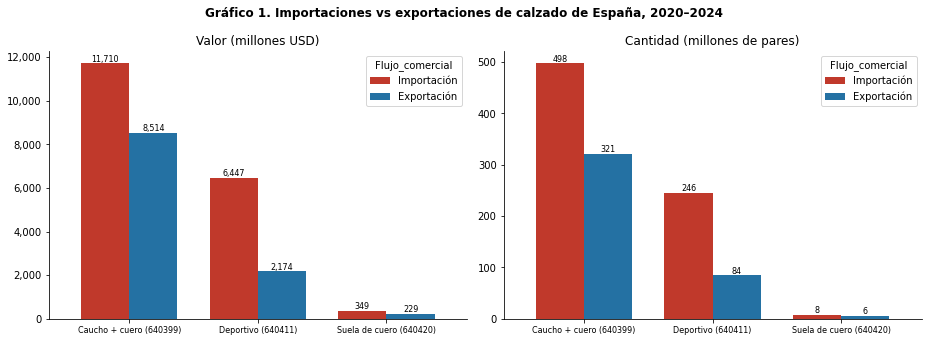

In [11]:
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COLOR = {"Importación": "#C0392B", "Exportación": "#2471A3"}
orden_cat = ["Caucho + cuero (640399)", "Deportivo (640411)", "Suela de cuero (640420)"]

# Gráfico 1: Importaciones vs exportaciones por categoría (valor y pares)
t = ind_cat.reset_index()
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
for i, (col, titulo) in enumerate([("Valor_millones_USD", "Valor (millones USD)"), ("Pares_millones", "Cantidad (millones de pares)")]):
    p = t.pivot(index="Categoría_corta", columns="Flujo_comercial", values=col).loc[orden_cat, ["Importación", "Exportación"]]
    p.plot.bar(ax=ax[i], color=[COLOR[c] for c in p.columns], rot=0, width=0.75)
    ax[i].set_title(titulo); ax[i].set_xlabel(""); ax[i].yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
    for cont in ax[i].containers:
        ax[i].bar_label(cont, fmt="{:,.0f}", fontsize=8)
    ax[i].tick_params(axis="x", labelsize=8)
fig.suptitle("Gráfico 1. Importaciones vs exportaciones de calzado de España, 2020–2024", fontweight="bold")
plt.tight_layout(); plt.show()

**Interpretación:** España importa más de lo que exporta en las tres categorías, tanto en valor como en pares. La categoría *Caucho + cuero* concentra la mayor parte del comercio; *Suela de cuero* es un nicho pequeño.

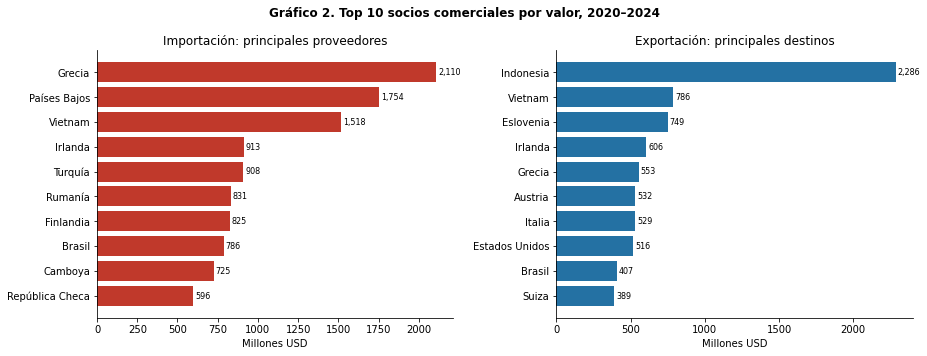

In [12]:
# Gráfico 2: Principales socios comerciales (top 10 por valor)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for i, flujo in enumerate(["Importación", "Exportación"]):
    top = socios[socios.Flujo_comercial == flujo].nlargest(10, "Valor_millones_USD").iloc[::-1]
    ax[i].barh(top["Socio_comercial"], top["Valor_millones_USD"], color=COLOR[flujo])
    ax[i].bar_label(ax[i].containers[0], fmt="{:,.0f}", fontsize=8, padding=2)
    ax[i].set_title(f"{flujo}: {'principales proveedores' if flujo == 'Importación' else 'principales destinos'}")
    ax[i].set_xlabel("Millones USD")
fig.suptitle("Gráfico 2. Top 10 socios comerciales por valor, 2020–2024", fontweight="bold")
plt.tight_layout(); plt.show()

**Interpretación:** el comercio está concentrado en pocos socios. Junto a proveedores asiáticos de bajo costo (Vietnam y Camboya en el top 10) aparecen países europeos, lo que sugiere reexportación o centros logísticos; algunos resultados (p. ej. Grecia como gran proveedor) parecen poco realistas y podrían reflejar **datos simulados**.

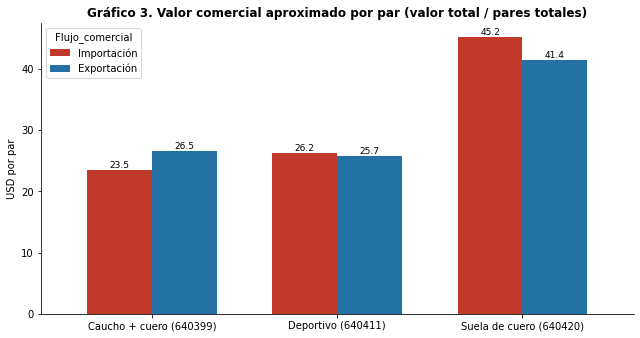

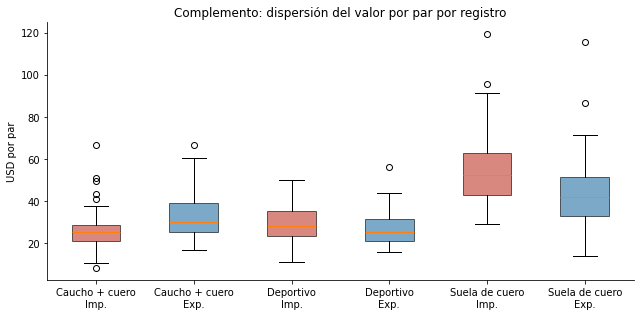

In [13]:
# Gráfico 3: Comparación de valor por par (ponderado) por categoría
p = ind_cat["USD_por_par_ponderado"].unstack(0).loc[orden_cat, ["Importación", "Exportación"]]
ax = p.plot.bar(color=[COLOR[c] for c in p.columns], rot=0, figsize=(9, 4.8), width=0.7)
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.1f", fontsize=9)
ax.set_ylabel("USD por par"); ax.set_xlabel("")
ax.set_title("Gráfico 3. Valor comercial aproximado por par (valor total / pares totales)", fontweight="bold")
plt.tight_layout(); plt.show()

# Complemento: distribución del valor por par por registro
fig, ax = plt.subplots(figsize=(9, 4.5))
datos = [df[(df.Categoría_corta == c) & (df.Flujo_comercial == f)]["Valor_USD_por_par"] for c in orden_cat for f in ["Importación", "Exportación"]]
etiquetas = [f"{c.split(' (')[0]}\n{f[:3]}." for c in orden_cat for f in ["Importación", "Exportación"]]
bp = ax.boxplot(datos, patch_artist=True)
ax.set_xticks(range(1, len(etiquetas) + 1), etiquetas)
for caja, f in zip(bp["boxes"], ["Importación", "Exportación"] * 3):
    caja.set_facecolor(COLOR[f]); caja.set_alpha(0.6)
ax.set_ylabel("USD por par"); ax.set_title("Complemento: dispersión del valor por par por registro")
plt.tight_layout(); plt.show()

**Interpretación:** el calzado con **suela de cuero** vale entre 41 y 45 USD por par, casi el doble que las otras dos categorías (~24–27 USD). Es el segmento donde el producto importado *no* compite por precio bajo.

## 5. Exportar la tabla depurada

In [14]:
df.to_excel("Manaco_tabla_depurada.xlsx", index=False)
try:
    from google.colab import files
    files.download("Manaco_tabla_depurada.xlsx")
except ImportError:
    print("Archivo guardado: Manaco_tabla_depurada.xlsx")

Archivo guardado: Manaco_tabla_depurada.xlsx


## 6. Síntesis ejecutiva

**Hallazgos**
1. **España es importadora neta de calzado:** importa ~18.506 millones USD (751 millones de pares) y exporta ~10.917 millones USD (411 millones de pares); la tasa de cobertura es ~59 %. Muestra un mercado muy expuesto al calzado importado, el mismo tipo de presión que enfrenta Manaco.
2. **Valor y cantidad cuentan historias distintas:** *Caucho + cuero (640399)* domina en volumen y valor, pero *Suela de cuero (640420)* —con apenas ~1 % de los pares— tiene un valor por par de 41–45 USD, casi el doble que el resto. El cuero es un nicho de **mayor valor unitario**.
3. **Socios concentrados y presencia asiática:** los 3 principales proveedores (Grecia, Países Bajos y Vietnam) suman ~29 % del valor importado, e Indonesia sola recibe ~21 % del valor exportado. Vietnam está en el top 3 de ambos flujos y entre los proveedores aparecen países de bajo costo (Vietnam, Camboya, China, Bangladesh, India).

**Limitaciones**
1. **No son datos de Manaco ni de Bolivia:** es comercio reportado por España; sirve como referencia externa, pero no mide ventas, costos ni clientes de Manaco. Además, los datos parecen en parte simulados (socios poco realistas).
2. **Calidad y cobertura de la base:** años desbalanceados (28 registros en 2020 vs 82 en 2024), sin registros "Mundo" para validar totales, 10 claves repetidas con valores distintos y valor por par aduanero que no equivale al precio al consumidor.

**Pregunta estratégica para Manaco**
> ¿Debe Manaco concentrar su diferenciación en calzado de cuero de mayor valor por par —donde la competencia importada no compite por precio— y qué datos internos (margen por línea, ventas por región, rotación de inventario, defectos y devoluciones) necesita para confirmar que ese segmento es más rentable?